# Response-rate sensitivity analyses

Author: Tien Tyler Le 

Date: 07/08/2026



Two evidence artifacts for the synthetic generator + decision methods, built on the MSSD-based JITAI
decision engine in `syntheticData/decision/`:

All results are on the production 1–7 Likert scale (re-run 2026-10-12; the earlier 1–5 runs are superseded).

TLDR:

- High response rate good. Recovers both volatility ($\sigma$) and autocorrelation ($\rho$) better. 
- $\rho$ is more sensitive to response rate, but on 1–7 the $\sigma$ effect is also significant
- MSSD recovery improves as response rate goes up.
    - Because we can understand a participant's volatility and autocorrelation better. Hence, our threshold is less noisy, bringing more precision. 
    - Accuracy is only determine if we mirror the participant's actual underlying behavioral state (user feedback), which can be helped with data completeness. 

Hence, aiming for >70% response rate from participants is ideal. 

# Problem Statement

Parameter Recovery suggests that Response rate may have an effect on $\rho$ and $\sigma$ recovery. However, we do not know if it is a causation or correlation from another factors, such as the prompt thresholds, or number of EMA observations.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

%matplotlib inline

HERE = os.getcwd()
REPO = HERE
while REPO != os.path.dirname(REPO) and not os.path.isdir(
        os.path.join(REPO, "backend", "decision_engine")):
    REPO = os.path.dirname(REPO)
if not os.path.isdir(os.path.join(REPO, "backend", "decision_engine")):
    raise RuntimeError("run this notebook from inside the REACT repo")

for p in (os.path.join(REPO, "backend"),
          os.path.join(REPO, "backend", "syntheticData"),
          os.path.join(REPO, "analytics", "sensitivity_analysis")):
    if p not in sys.path:
        sys.path.insert(0, p)

from synthetic_generator import generate_cohort
from decision_engine.decision_engine import calculate_mssd, apply_decision_rules
from decision_engine.run_decision_engine import build_decisions, spread_ema_timestamps
from mssd_validation import recover_ar1_params, empirical_mssd

# Sensitivity Analysis

0. **Decision-log parameter recovery**
   - Recovery of σ, ρ and MSSD on the cohort `run_decision_engine.build_decisions` produces.
   - Same recovery split by response rate and by answered observations.

1. **Threshold sensitivity grid** 
   - Response rate tested: *70–90%*
   - Burn-in length: how long to collect data before triggering intervention prompts per participant per week
   - Characterizes the JITAI dosage a study would deliver under different
   compliance and warm-up assumptions.

2. **Recovery question** | does response rate significantly affect recovery of
   - the latent AR(1) parameters (ρ, σ) and the MSSD signal? 
   - response-rate sweep plus regression / ANOVA.



In [2]:
BASE = os.path.join(REPO, "analytics", "sensitivity_analysis")
FIGURE_DIR = os.path.join(BASE, "figures")
OUTPUT_DIR = os.path.join(BASE, "outputs")
os.makedirs(FIGURE_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# same decision rule as the decision engine
THRESHOLD_QUANTILE = 0.80
COOLDOWN_MINUTES = 60
MAX_PROMPTS_PER_DAY = 4
MSSD_WINDOW = 3
SEED = 42

# production EMA scale (MinValueValidator(1) / MaxValueValidator(7))
LIKERT_MIN, LIKERT_MAX = 1, 7
print("setup ok")

setup ok


## Decision-log parameter recovery

The cohort is `backend/decision_engine/run_decision_engine.py::build_decisions`: 100 participants,
7 days, 5 EMA/day, a nominal response rate stepping 0.65–0.93 across participants with clustered
missingness, run through the production decision engine. Responses are on the production 1–7
scale. A participant is analysed when they answered at least `MIN_ANSWERED` prompts and both
$\hat\sigma$ and $\hat\rho$ are defined.

Writes `per_user_summary.csv`, `param_recovery_decision_log.png`, `mssd_recovery_decision_log.png`
and `recovery_by_data_availability.png` to `figures/`.

In [3]:
DL_USERS, DL_DAYS, DL_EMA_PER_DAY, DL_SEED = 100, 7, 5, 42
MIN_ANSWERED = 10

decisions = build_decisions(users=DL_USERS, days=DL_DAYS,
                            ema_per_day=DL_EMA_PER_DAY, seed=DL_SEED)
answered = decisions["ema"].dropna()
assert answered.between(LIKERT_MIN, LIKERT_MAX).all() and answered.max() > 5, \
    "decision-log cohort is not on the 1-7 scale"

rows = []
for uid, g in decisions.groupby("user_id"):
    ema = g.sort_values("timestamp")["ema"].to_numpy(dtype=float)
    rho_hat, sigma_hat = recover_ar1_params(ema)
    rows.append({
        "user_id": uid,
        "true_sigma": float(g["true_sigma"].iloc[0]),
        "true_rho": float(g["true_rho"].iloc[0]),
        "true_expected_mssd": float(g["true_expected_mssd"].iloc[0]),
        "empirical_mssd": empirical_mssd(ema),
        "rho_hat": rho_hat,
        "sigma_hat": sigma_hat,
        "n_ema_answered": int(np.sum(~np.isnan(ema))),
        "n_ema_total": int(ema.size),
        "send_prompt_count": int(g["send_prompt"].sum()),
    })
per_user = pd.DataFrame(rows)
dl = (per_user[per_user["n_ema_answered"] >= MIN_ANSWERED]
      .dropna(subset=["empirical_mssd", "rho_hat", "sigma_hat"])
      .reset_index(drop=True))
dl.to_csv(os.path.join(FIGURE_DIR, "per_user_summary.csv"), index=False)
dl["resp_rate"] = dl["n_ema_answered"] / dl["n_ema_total"]

dl_r = stats.pearsonr(dl["true_expected_mssd"], dl["empirical_mssd"])
print(f"scale {LIKERT_MIN}-{LIKERT_MAX} | answered range {answered.min():.0f}-{answered.max():.0f}")
print(f"analysed {len(dl)} of {len(per_user)} participants (>= {MIN_ANSWERED} answered)")
print(f"MSSD Pearson r = {dl_r.statistic:.3f} (p = {dl_r.pvalue:.1e}), "
      f"Spearman = {stats.spearmanr(dl['true_expected_mssd'], dl['empirical_mssd']).statistic:.3f}")
print(f"sigma r = {stats.pearsonr(dl['true_sigma'], dl['sigma_hat']).statistic:.3f}, "
      f"rho r = {stats.pearsonr(dl['true_rho'], dl['rho_hat']).statistic:.3f}")
print(f"mean empirical MSSD {dl['empirical_mssd'].mean():.3f} vs "
      f"mean true expected {dl['true_expected_mssd'].mean():.3f}")
print(f"mean realised response rate {dl['resp_rate'].mean():.3f}")
print()
print(decisions["decision_reason"].value_counts(normalize=True).round(4).to_string())

scale 1-7 | answered range 1-7
analysed 100 of 100 participants (>= 10 answered)
MSSD Pearson r = 0.849 (p = 5.9e-29), Spearman = 0.871
sigma r = 0.888, rho r = 0.552
mean empirical MSSD 1.086 vs mean true expected 1.107
mean realised response rate 0.791

decision_reason
below within-person threshold         0.5134
missing or insufficient EMA data      0.2783
prompt sent                           0.1283
insufficient within-person history    0.0794
daily cap reached                     0.0006


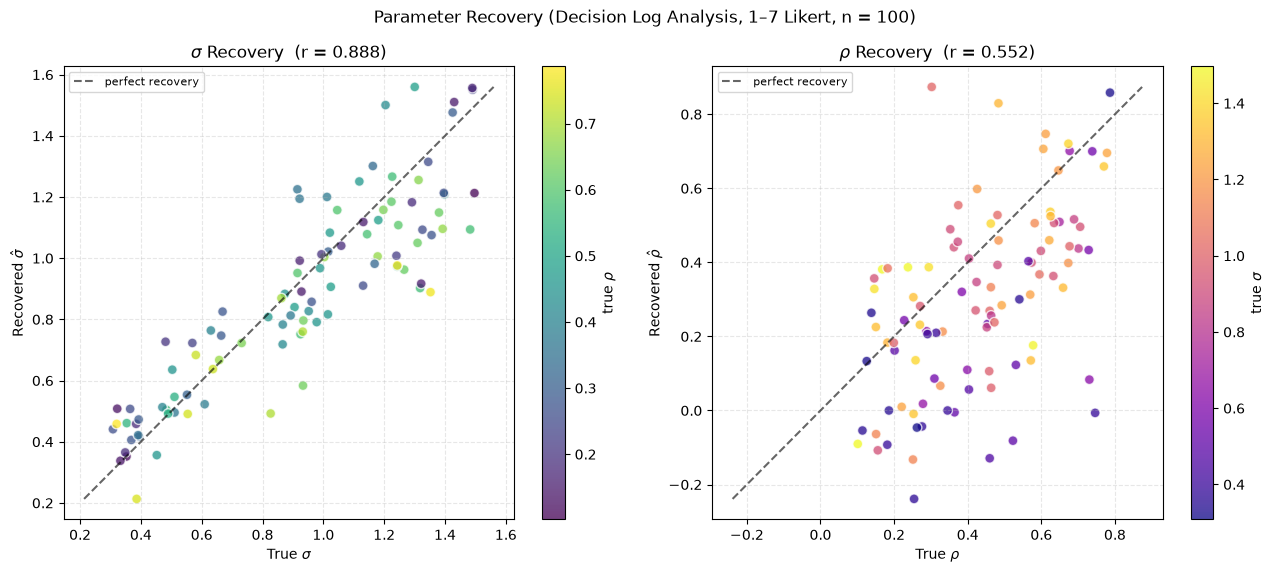

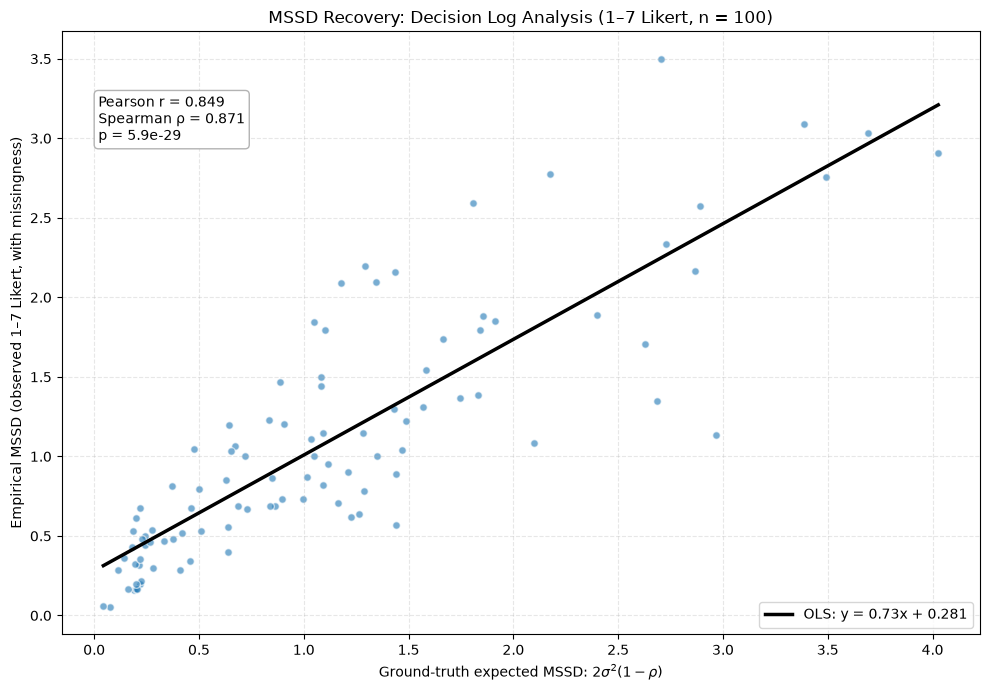

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))
for ax, param, other, cmap in ((axes[0], "sigma", "rho", "viridis"),
                               (axes[1], "rho", "sigma", "plasma")):
    true, rec = dl[f"true_{param}"], dl[f"{param}_hat"]
    sc = ax.scatter(true, rec, c=dl[f"true_{other}"], cmap=cmap, s=50,
                    alpha=0.75, edgecolor="white")
    lo, hi = min(true.min(), rec.min()), max(true.max(), rec.max())
    ax.plot([lo, hi], [lo, hi], "k--", alpha=0.6, label="perfect recovery")
    r = stats.pearsonr(true, rec).statistic
    ax.set_xlabel(f"True $\\{param}$")
    ax.set_ylabel(f"Recovered $\\hat{{\\{param}}}$")
    ax.set_title(f"$\\{param}$ Recovery  (r = {r:.3f})")
    ax.grid(True, linestyle="--", alpha=0.3)
    ax.legend(loc="upper left", fontsize=8)
    fig.colorbar(sc, ax=ax, label=f"true $\\{other}$")
fig.suptitle(f"Parameter Recovery (Decision Log Analysis, {LIKERT_MIN}–{LIKERT_MAX} Likert, n = {len(dl)})")
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "param_recovery_decision_log.png"), bbox_inches="tight")
plt.show()

x, y = dl["true_expected_mssd"].to_numpy(), dl["empirical_mssd"].to_numpy()
fit = stats.linregress(x, y)
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(x, y, s=30, alpha=0.6, color="tab:blue", edgecolor="white")
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, fit.slope * xs + fit.intercept, color="black", lw=2.5,
        label=f"OLS: y = {fit.slope:.2f}x + {fit.intercept:.3f}")
ax.annotate(f"Pearson r = {fit.rvalue:.3f}\n"
            f"Spearman ρ = {stats.spearmanr(x, y).statistic:.3f}\n"
            f"p = {fit.pvalue:.1e}",
            xy=(0.04, 0.82), xycoords="axes fraction",
            bbox=dict(boxstyle="round", fc="white", ec="0.7"))
ax.set_xlabel(r"Ground-truth expected MSSD: $2\sigma^2(1-\rho)$")
ax.set_ylabel(f"Empirical MSSD (observed {LIKERT_MIN}–{LIKERT_MAX} Likert, with missingness)")
ax.set_title(f"MSSD Recovery: Decision Log Analysis ({LIKERT_MIN}–{LIKERT_MAX} Likert, n = {len(dl)})")
ax.grid(True, linestyle="--", alpha=0.3)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "mssd_recovery_decision_log.png"), bbox_inches="tight")
plt.show()

by response rate
  mid  n  MSSD     ρ     σ
 0.3  4 0.927 0.959 0.365
 0.5 13 0.847 0.798 0.910
 0.7 29 0.819 0.325 0.894
 0.9 54 0.889 0.617 0.897

by answered observations
    mid  n  MSSD     ρ     σ
12.488  5 0.931 0.948 0.541
17.500  9 0.749 0.765 0.939
22.500 17 0.947 0.178 0.847
27.500 27 0.756 0.512 0.867
32.500 42 0.891 0.637 0.912


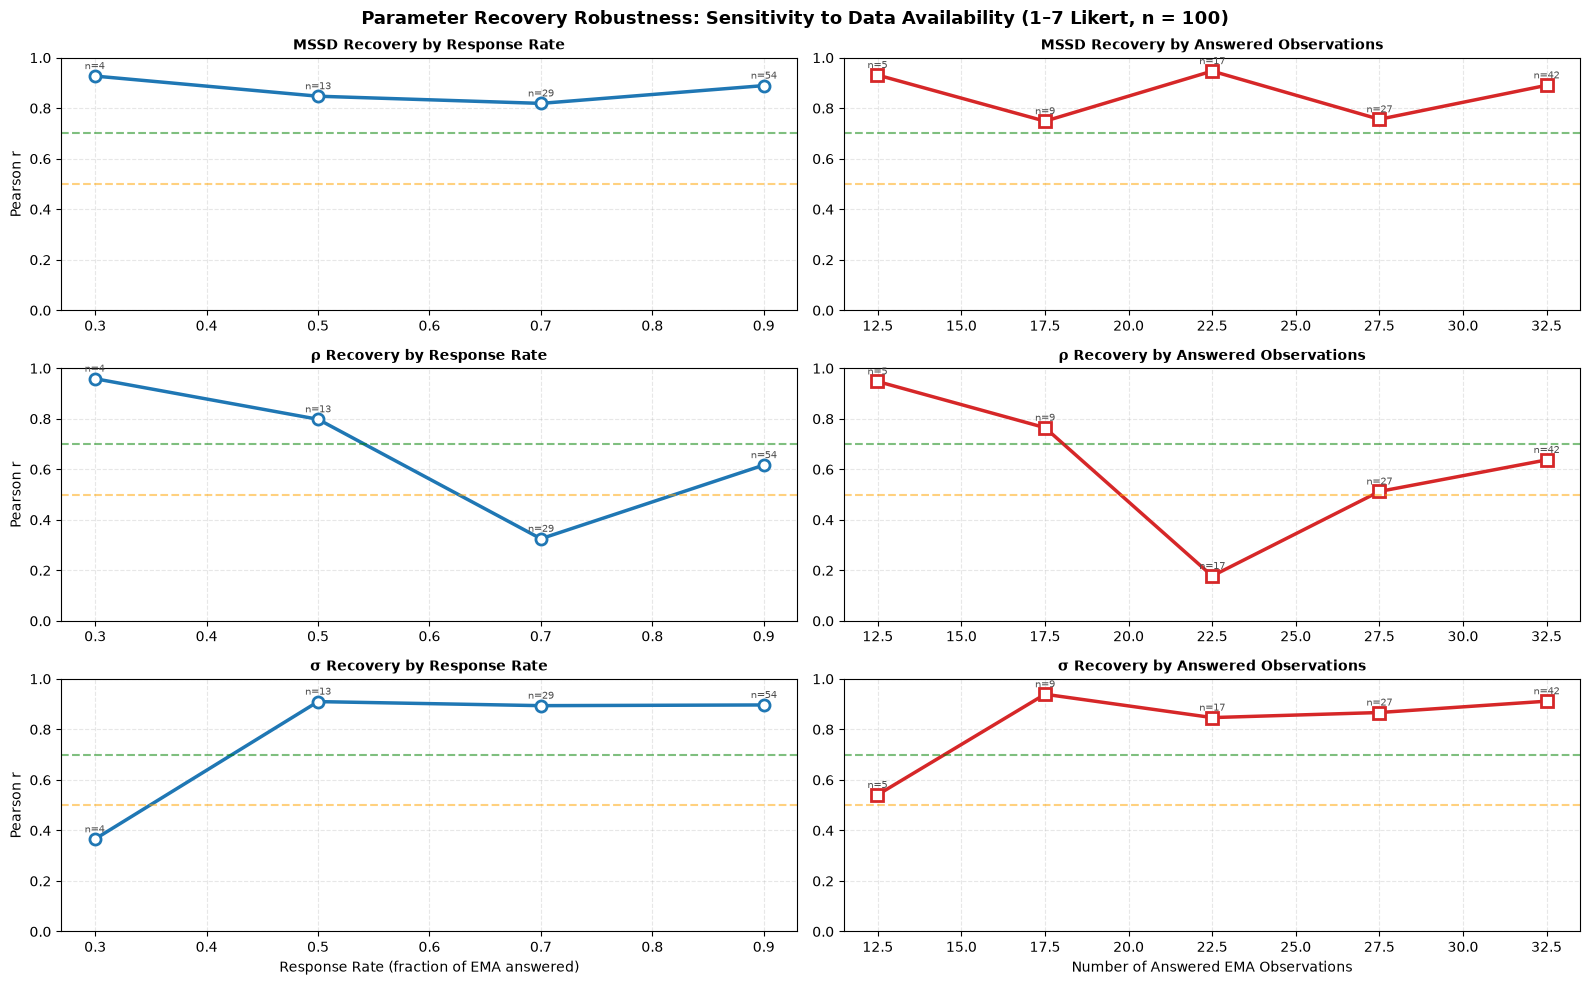

In [5]:
RECOVERY_PAIRS = [("MSSD", "true_expected_mssd", "empirical_mssd"),
                  ("ρ", "true_rho", "rho_hat"),
                  ("σ", "true_sigma", "sigma_hat")]


def recovery_by_bin(df, bins):
    """Pearson r of true vs recovered per bin; NaN where a bin has < 3 participants."""
    out = []
    for b, g in df.groupby(bins, observed=True):
        row = {"mid": b.mid, "n": len(g)}
        for label, t, h in RECOVERY_PAIRS:
            row[label] = stats.pearsonr(g[t], g[h]).statistic if len(g) >= 3 else np.nan
        out.append(row)
    return pd.DataFrame(out)


by_rate = recovery_by_bin(dl, pd.cut(dl["resp_rate"], [0.2, 0.4, 0.6, 0.8, 1.0],
                                     include_lowest=True))
by_obs = recovery_by_bin(dl, pd.cut(dl["n_ema_answered"], 5))
print("by response rate\n", by_rate.round(3).to_string(index=False))
print("\nby answered observations\n", by_obs.round(3).to_string(index=False))

floor = min(0.0, np.nanmin(np.r_[by_rate[["MSSD", "ρ", "σ"]].to_numpy().ravel(),
                                 by_obs[["MSSD", "ρ", "σ"]].to_numpy().ravel()]) - 0.05)
fig, axes = plt.subplots(3, 2, figsize=(16, 10))
for i, (label, _, _) in enumerate(RECOVERY_PAIRS):
    for j, (tab, color, marker, xname) in enumerate((
            (by_rate, "tab:blue", "o", "Response Rate"),
            (by_obs, "tab:red", "s", "Answered Observations"))):
        ax = axes[i, j]
        ax.plot(tab["mid"], tab[label], marker=marker, color=color, lw=2.5, ms=8,
                markerfacecolor="white", markeredgewidth=2)
        for xm, yv, n in zip(tab["mid"], tab[label], tab["n"]):
            if np.isfinite(yv):
                ax.annotate(f"n={n}", (xm, yv), textcoords="offset points",
                            xytext=(0, 5), ha="center", fontsize=7, color="0.3")
        ax.axhline(0.7, color="green", ls="--", alpha=0.5)
        ax.axhline(0.5, color="orange", ls="--", alpha=0.5)
        ax.set_ylim(floor, 1.0)
        ax.grid(True, linestyle="--", alpha=0.3)
        ax.set_title(f"{label} Recovery by {xname}", fontweight="bold", fontsize=10)
        if j == 0:
            ax.set_ylabel("Pearson r")
axes[2, 0].set_xlabel("Response Rate (fraction of EMA answered)")
axes[2, 1].set_xlabel("Number of Answered EMA Observations")
fig.suptitle(f"Parameter Recovery Robustness: Sensitivity to Data Availability "
             f"({LIKERT_MIN}–{LIKERT_MAX} Likert, n = {len(dl)})",
             fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "recovery_by_data_availability.png"), bbox_inches="tight")
plt.show()

## Threshold sensitivity grid

For each response-rate row we generate one cohort (latent σ/ρ/μ random, but the
**same** population across response rates via a fixed seed), run the decision
engine once, then read off each burn-in column by counting `send_prompt` events
**after** the warm-up window. During the burn-in the MSSD/threshold history still
accrues, but prompts fired there are not
counted. Counts are normalized to a 7-day week over the retained window
`(DAYS - burn_in_days)`. Holding the population fixed keeps each axis attributable
to the factor it manipulates (compliance vs. warm-up), not to resampling noise.

### pseudo

For each response-rate (70-90%):
- we generate one cohort w/ random σ/ρ/μ and a given warm-up window.
- same population across response rates w/ fixed seed.
- MSSD/threshold still gets recorded
- The decision threshold triggers after the warm-up window.


### variables tested 

Independents:
- MSSD
- Recovered $\rho$ / $\sigma$

Dependents:
- Response-rate
- Warm-up window (burn-ins)
- Sampling size
- Prompt Thresholds

In [6]:
def build_dosage_grid(threshold_quantiles, burn_in_days_list,
                      resp_rate=0.80, users=150, days=28,
                      ema_per_day=5, n_reps=10, seed=SEED):
    """
    threshold_quantile × burn_in_days grid of mean triggered prompts/week.

    Same participants in every threshold cell — only the decision gate changes:
      • generate cohort once per replication seed
      • calculate_mssd once per cohort  (MSSD identical across all tq values)
      • loop over threshold_quantile → apply_decision_rules → slice by burn-in

    Replications (n_reps seeds) let us average out realization noise and
    report n per cell.  Returns tidy DataFrame aggregated across users × reps.
    """
    recs = []
    for r in range(n_reps):
        cohort = generate_cohort(users=users, days=days, ema_per_day=ema_per_day,
                                 seed=seed + r, resp_rate=resp_rate,
                                 likert_min=LIKERT_MIN, likert_max=LIKERT_MAX)
        cohort = spread_ema_timestamps(cohort, ema_per_day)
        dec_mssd = calculate_mssd(cohort, window=MSSD_WINDOW)  # computed once

        for tq in threshold_quantiles:
            dec = apply_decision_rules(dec_mssd,
                                       threshold_quantile=tq,
                                       cooldown_minutes=COOLDOWN_MINUTES,
                                       max_prompts_per_day=MAX_PROMPTS_PER_DAY)
            for bd in burn_in_days_list:
                weeks = (days - bd) / 7.0
                post = dec[dec["day"] >= bd]
                per_user = post.groupby("user_id")["send_prompt"].sum() / weeks
                for ppw in per_user:
                    recs.append({"threshold_quantile": tq,
                                 "burn_in_days": bd,
                                 "resp_rate": resp_rate,
                                 "prompts_per_week": float(ppw)})

    df = pd.DataFrame(recs)
    agg = (df.groupby(["threshold_quantile", "burn_in_days"])
             .agg(prompts_per_week=("prompts_per_week", "mean"),
                  ci95=("prompts_per_week",
                        lambda x: 1.96 * x.std(ddof=1) / np.sqrt(x.size)),
                  n=("prompts_per_week", "size"))
             .reset_index())
    return agg

In [7]:
THRESHOLD_QUANTILES = [0.70, 0.75, 0.80, 0.85, 0.90]
BURN_IN_DAYS        = [0, 1, 2, 3, 5, 7]
GRID_RESP_RATES     = [0.70, 0.80, 0.90]   # used in 3-panel figure
USERS_A, DAYS_A     = 150, 28
EMA_PER_DAY         = 5
N_REPS              = 10

# ── Primary heatmap at resp_rate = 0.80 ────────────────────────────────────
grid_df = build_dosage_grid(THRESHOLD_QUANTILES, BURN_IN_DAYS,
                            resp_rate=0.80, users=USERS_A, days=DAYS_A,
                            ema_per_day=EMA_PER_DAY, n_reps=N_REPS)
grid_df.to_csv(os.path.join(OUTPUT_DIR, "threshold_sensitivity_grid.csv"), index=False)

grid_mat = grid_df.pivot(index="threshold_quantile", columns="burn_in_days",
                         values="prompts_per_week")
grid_n   = grid_df.pivot(index="threshold_quantile", columns="burn_in_days", values="n")

print(f"grid shape {grid_mat.shape}  | n per cell = {grid_n.iloc[0, 0]} (users × reps)")
print("all finite & ≥ 0:",
      bool(np.isfinite(grid_mat.values).all() and (grid_mat.values >= 0).all()))
grid_mat.round(2)

grid shape (5, 6)  | n per cell = 1500 (users × reps)
all finite & ≥ 0: True


burn_in_days,0,1,2,3,5,7
threshold_quantile,,,,,,
0.70,6.46,6.63,6.58,6.55,6.48,6.42
0.75,5.45,5.59,5.52,5.48,5.41,5.35
0.80,4.48,4.59,4.50,4.45,4.36,4.29
0.85,3.55,3.63,3.52,3.45,3.34,3.28
0.90,2.56,2.60,2.47,2.40,2.28,2.22


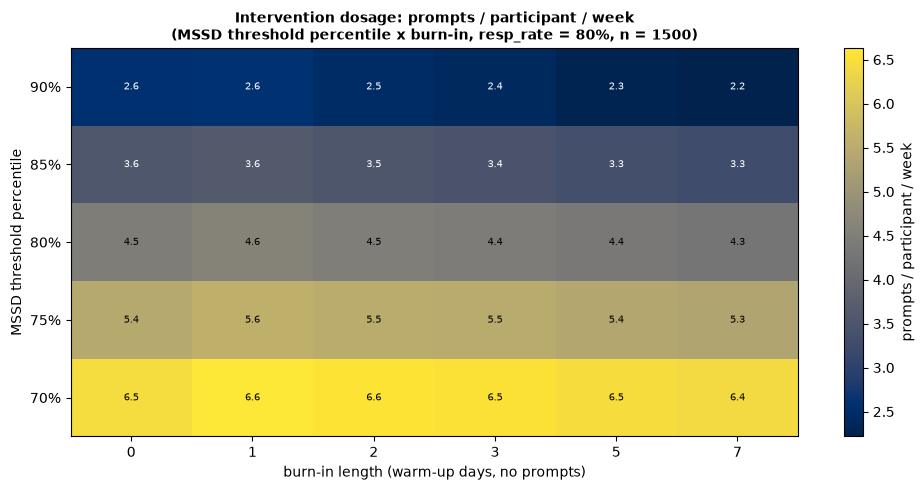

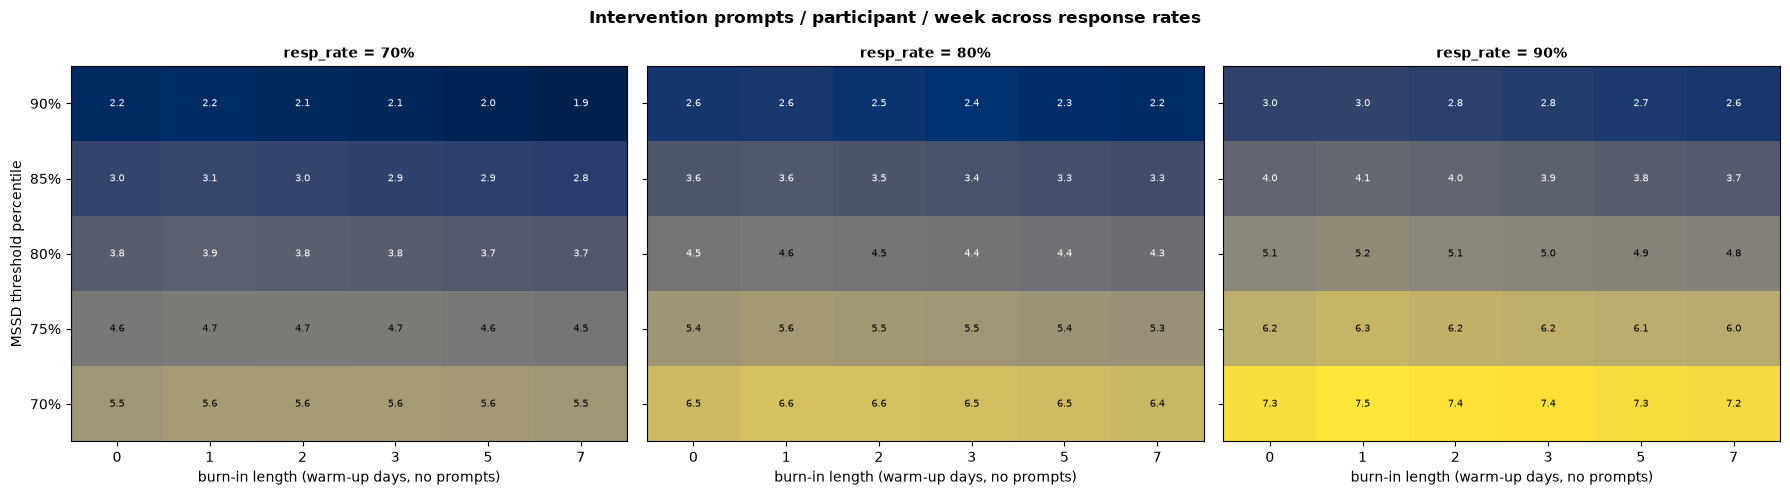

In [8]:
def draw_grid_heatmap(ax, mat_df, n_df, title, vmin=None, vmax=None):
    """Draw one threshold × burn-in heatmap on ax; return the imshow object."""
    mat = mat_df.to_numpy()
    n   = n_df.to_numpy()
    im = ax.imshow(mat, aspect="auto", origin="lower", cmap="cividis",
                   vmin=vmin, vmax=vmax)
    ax.set_xticks(range(mat_df.shape[1]))
    ax.set_xticklabels(mat_df.columns)
    ax.set_yticks(range(mat_df.shape[0]))
    ax.set_yticklabels([f"{q:.0%}" for q in mat_df.index])
    ax.set_xlabel("burn-in length (warm-up days, no prompts)")
    ax.set_ylabel("MSSD threshold percentile")
    ax.set_title(title, fontsize=10, fontweight="bold")
    thresh = (vmax or np.nanmax(mat)) * 0.6
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            ax.text(j, i, f"{mat[i, j]:.1f}",
                    ha="center", va="center", fontsize=7.5,
                    color="white" if mat[i, j] < thresh else "black")
    return im

# ── Primary single heatmap (resp_rate = 0.80) 
fig, ax = plt.subplots(figsize=(10, 5))
im = draw_grid_heatmap(ax, grid_mat, grid_n,
                       "Intervention dosage: prompts / participant / week\n"
                       "(MSSD threshold percentile x burn-in, resp_rate = 80%, n = 1500)")
fig.colorbar(im, ax=ax, label="prompts / participant / week")
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "threshold_sensitivity_grid.png"),
            bbox_inches="tight")
plt.show()

# ── 3-panel figure across response rates 
panel_data = {}
for rr in GRID_RESP_RATES:
    gd = build_dosage_grid(THRESHOLD_QUANTILES, BURN_IN_DAYS,
                           resp_rate=rr, users=USERS_A, days=DAYS_A,
                           ema_per_day=EMA_PER_DAY, n_reps=N_REPS)
    panel_data[rr] = (gd.pivot(index="threshold_quantile", columns="burn_in_days",
                                values="prompts_per_week"),
                      gd.pivot(index="threshold_quantile", columns="burn_in_days",
                                values="n"))

all_vals = np.concatenate([m.values for m, _ in panel_data.values()])
vmin, vmax = np.nanmin(all_vals), np.nanmax(all_vals)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, rr in zip(axes, GRID_RESP_RATES):
    m, n = panel_data[rr]
    im = draw_grid_heatmap(ax, m, n,
                           f"resp_rate = {rr:.0%}", vmin=vmin, vmax=vmax)
axes[0].set_ylabel("MSSD threshold percentile")
for ax in axes[1:]:
    ax.set_ylabel("")

fig.suptitle("Intervention prompts / participant / week across response rates",
             fontsize=12, fontweight="bold")
#fig.colorbar(im, ax=axes, label="prompts / participant / week", shrink=0.8)
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "threshold_sensitivity_grid_by_resprate.png"),
            bbox_inches="tight")
plt.show()

### Interpretation of the threshold sensitivity grid

The 80th-percentile within-person MSSD
threshold is a design choice.

- **Rows (threshold percentile, 70–90%)**: a lower percentile means more MSSD
  observations exceed the bar → more intervention prompts sent. Moving from 70%
  to 90% is the main dial for dosage control.
- **Columns (burn-in days, 0–7)**: warm-up days where history accrues but
  prompts aren't counted. Longer burn-in reduces the effective study window, so
  prompts/week are normalized to the post-warm-up period only.
- **n per cell** = 150 users × 10 replications = 1 500 user-weeks, giving
  stable cell estimates.
- The 3-panel version (70 / 80 / 90% response rate) shows how compliance shifts
  the entire grid up or down without changing its shape 
    - This confirms that response rate and threshold are separable dials in the design space.

----------------
## Response rate vs ρ/σ recovery and MSSD

Sweep response rate across levels, drawing a fresh population (random latent
σ/ρ) at each level, recover the AR(1) parameters and empirical MSSD per user,
then test whether recovery error and the MSSD <-> latent relationship depend on
response rate (linear regression across users + one-way ANOVA across levels).

We're trying to answer:

- **Does parameter recovery and MSSD really gets affected by MSSD?**

In [9]:
def run_recovery_sweep(resp_rates, users_per_level=200, days=14, ema_per_day=5, seed=SEED):
    """One row per user across all response-rate levels: true vs recovered
    (σ, ρ), empirical vs expected MSSD, and answered-count."""
    recs = []
    for k, rr in enumerate(resp_rates):
        cohort = generate_cohort(users=users_per_level, days=days,
                                 ema_per_day=ema_per_day, seed=seed + 1000 + k,
                                 resp_rate=rr,
                                 likert_min=LIKERT_MIN, likert_max=LIKERT_MAX)
        for uid, g in cohort.groupby("user_id"):
            g = g.sort_values("prompt_idx")
            ema = g["ema"].to_numpy()
            rho_hat, sigma_hat = recover_ar1_params(ema)
            recs.append({
                "resp_rate": rr,
                "user_id": uid,
                "true_sigma": float(g["true_sigma"].iloc[0]),
                "true_rho": float(g["true_rho"].iloc[0]),
                "true_expected_mssd": float(g["true_expected_mssd"].iloc[0]),
                "sigma_hat": sigma_hat,
                "rho_hat": rho_hat,
                "empirical_mssd": empirical_mssd(ema),
                "n_answered": int(np.sum(~np.isnan(ema))),
            })
    df = pd.DataFrame(recs)
    df["abs_err_sigma"] = (df["sigma_hat"] - df["true_sigma"]).abs()
    df["abs_err_rho"] = (df["rho_hat"] - df["true_rho"]).abs()
    df["signed_err_sigma"] = df["sigma_hat"] - df["true_sigma"]
    df["signed_err_rho"] = df["rho_hat"] - df["true_rho"]
    return df

In [10]:
SWEEP_RESP_RATES = np.round(np.arange(0.50, 0.96, 0.05), 2) # [0.50, 0.55, 0.60, 0.65,... 0.95]
USERS_PER_LEVEL, DAYS_B = 200, 14

sweep_df = run_recovery_sweep(SWEEP_RESP_RATES, users_per_level=USERS_PER_LEVEL,
                              days=DAYS_B, ema_per_day=EMA_PER_DAY)
print("sweep rows:", len(sweep_df),
      "| levels:", sweep_df['resp_rate'].nunique())
sweep_df.head()

sweep rows: 2000 | levels: 10


,resp_rate,user_id,true_sigma,true_rho,true_expected_mssd,sigma_hat,rho_hat,empirical_mssd,n_answered,abs_err_sigma,abs_err_rho,signed_err_sigma,signed_err_rho
0,0.5,007c3b7b-227a-4e5f-81fe-70fb5d87bcb4,1.069774,0.644819,0.812949,1.082750,0.541345,0.809524,33,0.012976,0.103475,0.012976,-0.103475
1,0.5,00cfa0ab-b139-4ecb-aded-6d70750c5673,1.387157,0.558719,1.698229,1.355864,0.502644,1.700000,50,0.031293,0.056075,-0.031293,-0.056075
2,0.5,02797efc-d5d3-4d20-9a25-b1f4baf21d4a,0.485853,0.437567,0.265528,0.749797,0.229731,0.961538,41,0.263944,0.207835,0.263944,-0.207835
3,0.5,030bdf28-a9a5-4532-8584-4baee4d3fe17,0.743294,0.545514,0.502194,0.637344,0.259858,0.517241,39,0.105949,0.285656,-0.105949,-0.285656
4,0.5,05d30908-5a5a-48dd-a10f-b8ef73b8c821,0.436208,0.366820,0.240960,0.534047,0.198402,0.440000,38,0.097839,0.168418,0.097839,-0.168418


In [11]:
# --- Significance tests 
def ci95(x):
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    if x.size < 2:
        return np.nan
    return 1.96 * x.std(ddof=1) / np.sqrt(x.size)

# Per-level aggregates (mean abs err + 95% CI, and within-level MSSD Pearson r).
per_level_rows = []
for rr, grp in sweep_df.groupby("resp_rate"):
    sub = grp.dropna(subset=["empirical_mssd", "true_expected_mssd"])
    mssd_r = stats.pearsonr(sub["true_expected_mssd"], sub["empirical_mssd"])[0] \
        if len(sub) >= 3 else np.nan
    per_level_rows.append({
        "resp_rate": rr,
        "n": len(grp),
        "mean_abs_err_sigma": grp["abs_err_sigma"].mean(),
        "ci_abs_err_sigma": ci95(grp["abs_err_sigma"]),
        "mean_abs_err_rho": grp["abs_err_rho"].mean(),
        "ci_abs_err_rho": ci95(grp["abs_err_rho"]),
        "mssd_pearson_r": mssd_r,
    })
per_level = pd.DataFrame(per_level_rows).sort_values("resp_rate").reset_index(drop=True)

# Regression of per-user recovery error on response rate (across all users).
vs = sweep_df.dropna(subset=["abs_err_sigma"])
vr = sweep_df.dropna(subset=["abs_err_rho"])
reg_sigma = stats.linregress(vs["resp_rate"], vs["abs_err_sigma"])
reg_rho = stats.linregress(vr["resp_rate"], vr["abs_err_rho"])

# One-way ANOVA: does mean recovery error differ across response-rate levels?
grp_sigma = [g["abs_err_sigma"].dropna().to_numpy() for _, g in sweep_df.groupby("resp_rate")]
grp_rho = [g["abs_err_rho"].dropna().to_numpy() for _, g in sweep_df.groupby("resp_rate")]
anova_sigma = stats.f_oneway(*grp_sigma)
anova_rho = stats.f_oneway(*grp_rho)

# Does the MSSD<->latent relationship strengthen with response rate?
pl = per_level.dropna(subset=["mssd_pearson_r"])
reg_mssd_r = stats.linregress(pl["resp_rate"], pl["mssd_pearson_r"])

stats_block = pd.DataFrame([
    {"metric": "abs_err_sigma ~ resp_rate", "slope": reg_sigma.slope,
     "r_squared": reg_sigma.rvalue ** 2, "p_value": reg_sigma.pvalue,
     "anova_F": anova_sigma.statistic, "anova_p": anova_sigma.pvalue},
    {"metric": "abs_err_rho ~ resp_rate", "slope": reg_rho.slope,
     "r_squared": reg_rho.rvalue ** 2, "p_value": reg_rho.pvalue,
     "anova_F": anova_rho.statistic, "anova_p": anova_rho.pvalue},
    {"metric": "mssd_pearson_r ~ resp_rate", "slope": reg_mssd_r.slope,
     "r_squared": reg_mssd_r.rvalue ** 2, "p_value": reg_mssd_r.pvalue,
     "anova_F": np.nan, "anova_p": np.nan},
])

per_level.to_csv(os.path.join(OUTPUT_DIR, "recovery_vs_response_rate.csv"), index=False)
stats_block.to_csv(os.path.join(OUTPUT_DIR, "recovery_vs_response_rate_stats.csv"), index=False)

print(per_level.round(4).to_string(index=False))
print()
print(stats_block.round(5).to_string(index=False))

 resp_rate   n  mean_abs_err_sigma  ci_abs_err_sigma  mean_abs_err_rho  ci_abs_err_rho  mssd_pearson_r
      0.50 200              0.1117            0.0117            0.2093          0.0229          0.8434
      0.55 200              0.1149            0.0127            0.1830          0.0212          0.9008
      0.60 200              0.1065            0.0116            0.1584          0.0170          0.8984
      0.65 200              0.1016            0.0115            0.1590          0.0202          0.9073
      0.70 200              0.1048            0.0114            0.1604          0.0178          0.9090
      0.75 200              0.0973            0.0113            0.1565          0.0170          0.9319
      0.80 200              0.0903            0.0102            0.1492          0.0161          0.9153
      0.85 200              0.0920            0.0100            0.1357          0.0146          0.9485
      0.90 200              0.0845            0.0092            0.1280   

# ANOVA Interpretation

1–7 Likert, 200 participants per level, 10 levels (0.50–0.95).

$|Error(Volatility)|$ : 
- Slope = -0.062 per unit response rate (p = 5e-07); ANOVA F = 3.24, p = 0.0007
- $\sigma$ error falls from ~0.11 at 50% to ~0.09 at 80%+. Small in absolute terms, but significant
- This differs from the earlier 1–5 run (slope -0.027, p = 0.068, ANOVA p = 0.50). On 1–5, clipping at the scale ends dominated $\sigma$ error at every response rate and masked the missingness effect

$|Error(Autocorrelation)|$ : 
- Slope = -0.167 (p = 9e-17); ANOVA F = 8.85, p < 1e-4. Unchanged from 1–5 (-0.163)
- $\rho$ remains the parameter most sensitive to response rate: its slope is ~2.7x $\sigma$'s
- Hence, high $\rho$ recovery needs a high response rate *aka compliance from participants*

MSSD signal: within-level Pearson r rises from 0.84 at 50% to 0.93–0.95 at 85%+ (slope 0.173, p = 0.001), above the 0.70 benchmark at every level.

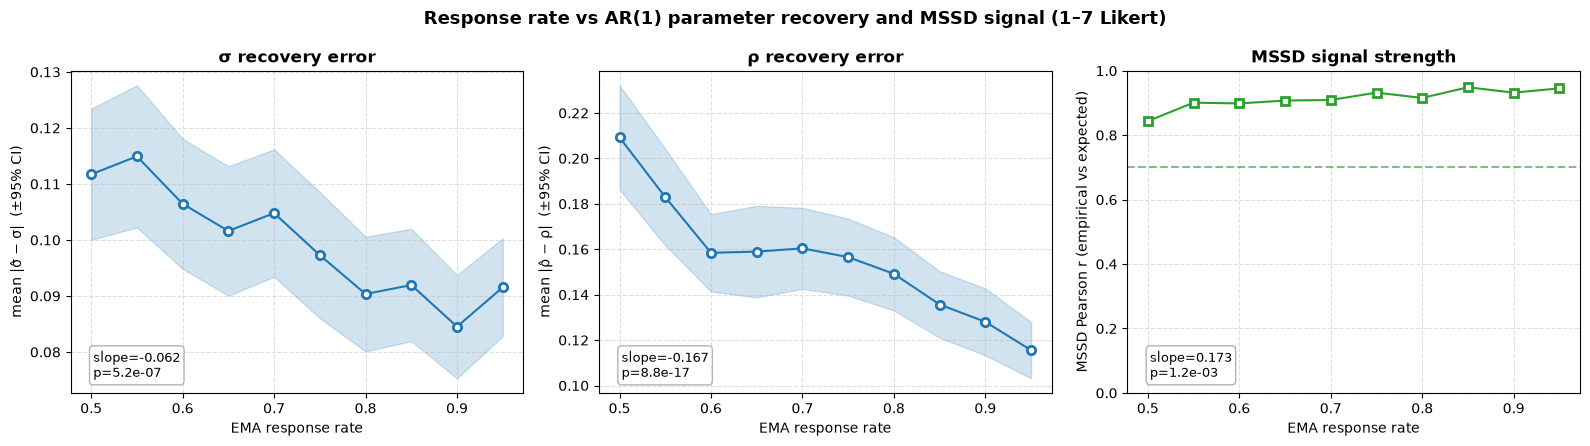

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

def err_panel(ax, mean_col, ci_col, reg, title, ylabel):
    x = per_level["resp_rate"].to_numpy()
    y = per_level[mean_col].to_numpy()
    ci = per_level[ci_col].to_numpy()
    ax.plot(x, y, "o-", color="tab:blue", markerfacecolor="white", markeredgewidth=2)
    ax.fill_between(x, y - ci, y + ci, alpha=0.2, color="tab:blue")
    ax.set_xlabel("EMA response rate")
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.annotate(f"slope={reg.slope:.3f}\np={reg.pvalue:.1e}",
                xy=(0.05, 0.05), xycoords="axes fraction",
                bbox=dict(boxstyle="round", fc="white", ec="0.7"), fontsize=9)

err_panel(axes[0], "mean_abs_err_sigma", "ci_abs_err_sigma", reg_sigma,
          "σ recovery error", "mean |σ̂ − σ|  (±95% CI)")
err_panel(axes[1], "mean_abs_err_rho", "ci_abs_err_rho", reg_rho,
          "ρ recovery error", "mean |ρ̂ − ρ|  (±95% CI)")

x = per_level["resp_rate"].to_numpy()
axes[2].plot(x, per_level["mssd_pearson_r"].to_numpy(), "s-", color="tab:green",
             markerfacecolor="white", markeredgewidth=2)
axes[2].axhline(0.7, color="green", linestyle="--", alpha=0.5)
axes[2].set_ylim(0, 1)
axes[2].set_xlabel("EMA response rate")
axes[2].set_ylabel("MSSD Pearson r (empirical vs expected)")
axes[2].set_title("MSSD signal strength", fontweight="bold")
axes[2].grid(True, linestyle="--", alpha=0.4)
axes[2].annotate(f"slope={reg_mssd_r.slope:.3f}\np={reg_mssd_r.pvalue:.1e}",
                 xy=(0.05, 0.05), xycoords="axes fraction",
                 bbox=dict(boxstyle="round", fc="white", ec="0.7"), fontsize=9)

fig.suptitle(f"Response rate vs AR(1) parameter recovery and MSSD signal ({LIKERT_MIN}–{LIKERT_MAX} Likert)",
             fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "recovery_vs_response_rate.png"),
            bbox_inches="tight")
plt.show()

## Findings

All on the production 1–7 Likert scale.

- **Decision-log recovery** (`param_recovery_decision_log.png`, `mssd_recovery_decision_log.png`,
  `recovery_by_data_availability.png`, `per_user_summary.csv`): n = 100. Empirical MSSD tracks true
  expected MSSD at r = 0.849 (Spearman 0.871), OLS slope 0.73. Mean empirical MSSD is 1.086 against
  a true 1.107. On 1–5 the same cohort gave r = 0.820, slope 0.54 and 0.939 vs 1.107: the wider
  scale clips less, so MSSD is less attenuated. $\sigma$ recovers at r = 0.888 and $\rho$ at r = 0.552,
  both essentially unchanged from 1–5.

- **Part A** (`threshold_sensitivity_grid.png`): the grid shows how the intervention dosage
  (eligible prompts / participant / week) moves with threshold percentile and burn-in length. At the
  80th percentile it is 4.48 with no burn-in and 4.29 after a 7-day burn-in, about 2.1 delivered after
  randomization at p = 0.5. Burn-in lowers dosage by about 0.2 at every percentile.
    - Rerun 2026-10-12 after fixing a duplicate row index in `generate_cohort`: `calculate_mssd` assigns
      the rolling MSSD back by index label, so repeated labels mixed participants and made the grid vary
      run to run (2.5–6.5 for the same seed). Every earlier grid number, on 1–5 or 1–7, is superseded.
    - Higher response rate feeds more answered EMAs into the within-person threshold.

- **Part B** (`recovery_vs_response_rate.csv`):

  - $\sigma$ recovery error falls with response rate (p = 5e-07), but the effect is small: about 0.02 between 50% and 95%.
  - Unlike $\sigma$, accurately capturing $\rho$ relies heavily on having a high response rate. If a participant skips too many prompts, our ability to estimate how their current mood/behavior carries over into the future ($\rho$) degrades significantly.
  - MSSD is only a reliable proxy when the user actually responds to EMAs, **so we need to aim for > 70% response rate from participants**.